In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/creditcard.csv")

In [3]:
df.sample(5).head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
131185,79516.0,-1.201172,-0.548377,2.631439,2.854492,0.579070,0.961969,-0.091708,0.221970,0.172547,...,-0.171671,-0.375741,0.168826,-0.451343,0.028046,0.021925,-0.066196,-0.071260,124.09,0
216034,140323.0,2.288565,-1.395657,-1.520785,-2.117561,-0.062430,1.359949,-1.388319,0.286223,-1.585573,...,-0.162012,-0.116451,0.380841,3.055718,-0.152907,-0.359923,-0.003056,-0.026882,19.95,0
209413,137548.0,1.998310,-0.183217,-1.030652,0.336527,-0.214763,-0.960212,0.035292,-0.147192,0.404015,...,-0.236904,-0.643245,0.343213,0.054431,-0.372494,0.174790,-0.081376,-0.069752,8.99,0
47363,43186.0,-0.058043,0.922296,1.481690,0.950782,-0.239376,-0.459817,0.311198,-0.061548,-0.906344,...,-0.071758,-0.224166,0.111362,0.557553,-0.651319,0.227822,-0.084265,0.040314,1.29,0
159423,112460.0,2.026420,-0.062076,-1.070051,0.414851,-0.074289,-1.110077,0.228597,-0.346032,0.449874,...,-0.268061,-0.635119,0.327407,0.003502,-0.298897,0.197589,-0.066425,-0.056769,16.00,0


In [4]:
print(df['Class'].value_counts())
print("==========")
df.isnull().sum().max()

Class
0    284315
1       492
Name: count, dtype: int64


np.int64(0)

In [5]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


Features V1–V28 appear to be standardized PCA components. Amount and Time are not standardized and may require scaling depending on the model.
No obvious feature-level or temporal data leakage was observed. All features appear anonymized and independent of the target label.


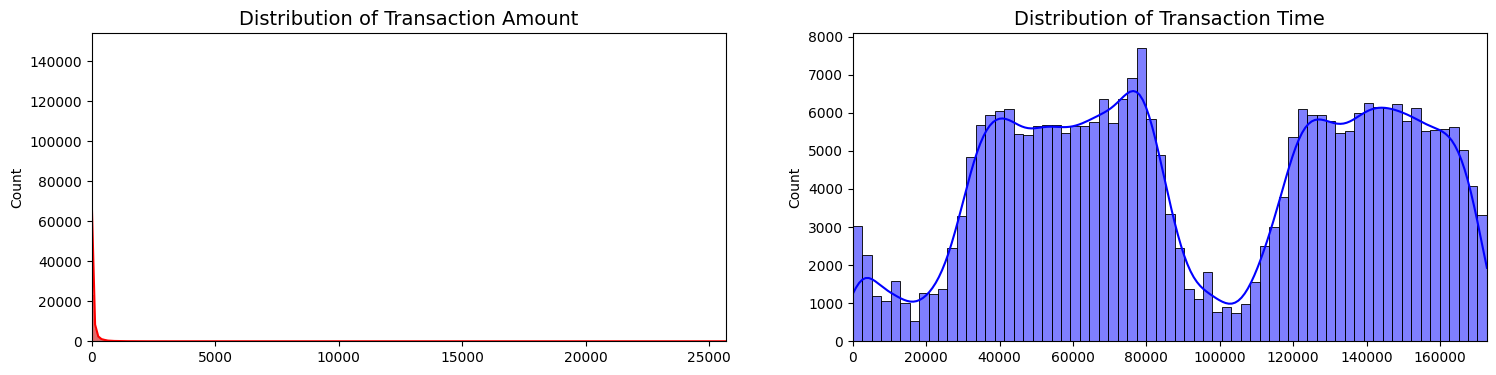

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(18,4))

amount_val = df['Amount'].values
time_val = df['Time'].values

sns.histplot(amount_val, ax=ax[0], color='r', kde=True)
ax[0].set_title('Distribution of Transaction Amount', fontsize=14)
ax[0].set_xlim([min(amount_val), max(amount_val)])

sns.histplot(time_val, ax=ax[1], color='b', kde=True)
ax[1].set_title('Distribution of Transaction Time', fontsize=14)
ax[1].set_xlim([min(time_val), max(time_val)])



plt.show()

In [7]:
df['Hour'] = (df['Time'] / 3600) % 24

df['Hour_Sin'] = np.sin(2 * np.pi * df['Hour'] / 24)
df['Hour_Cos'] = np.cos(2 * np.pi * df['Hour'] / 24)

df = df.drop(columns=['Time', 'Hour'])

print(df[['Hour_Sin', 'Hour_Cos', 'V1', 'Amount']].head())

   Hour_Sin  Hour_Cos        V1  Amount
0  0.000000       1.0 -1.359807  149.62
1  0.000000       1.0  1.191857    2.69
2  0.000073       1.0 -1.358354  378.66
3  0.000073       1.0 -0.966272  123.50
4  0.000145       1.0 -1.158233   69.99


In [8]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Class'])
y = df['Class']

X_temp, X_test, y_temp, y_test = train_test_split(
    X,
    y,
    test_size=0.15,
    stratify=y,
    random_state=42
)

X_train, X_val, y_train, y_val = train_test_split(
    X_temp,
    y_temp,
    test_size=0.1765,
    stratify=y_temp,
    random_state=42
)

print(y_train.value_counts(normalize=True))
y_val.value_counts(normalize=True)

Class
0    0.998274
1    0.001726
Name: proportion, dtype: float64


Class
0    0.998268
1    0.001732
Name: proportion, dtype: float64

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.preprocessing import StandardScaler

scaled_features = ["Amount"]
passthrough_features = [f"V{i}" for i in range(1, 29)] + ["Hour_Sin", "Hour_Cos"]

preprocessor = ColumnTransformer(
    transformers=[
        ("scale", RobustScaler(), scaled_features),
        ("pass", "passthrough", passthrough_features)
    ]
)


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("clf", LogisticRegression(
        max_iter=10000,
        solver="lbfgs"
    ))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_val)


In [11]:
from sklearn.calibration import CalibratedClassifierCV

calib_model_1 = CalibratedClassifierCV(model,
                                      method="sigmoid",
                                        cv=None)
calib_model_1.fit(X_val, y_val)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...iter=10000))])
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'sigmoid'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary ` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the co

In [12]:
calib_model_2 = CalibratedClassifierCV(model,
                                      method="isotonic",
                                        cv=None)
calib_model_2.fit(X_val, y_val)

,"estimator estimator: estimator instance, default=NoneThe classifier whose output need to be calibrated to provide moreaccurate `predict_proba` outputs. The default classifier isa :class:`~sklearn.svm.LinearSVC`... versionadded:: 1.2",Pipeline(step...iter=10000))])
,"method method: {'sigmoid', 'isotonic', 'temperature'}, default='sigmoid'The method to use for calibration. Can be:- 'sigmoid', which corresponds to Platt's method (i.e. a binary logistic regression model).- 'isotonic', which is a non-parametric approach.- 'temperature', temperature scaling.Sigmoid and isotonic calibration methods natively support only binaryclassifiers and extend to multi-class classification using a One-vs-Rest (OvR)strategy with post-hoc renormalization, i.e., adjusting the probabilities aftercalibration to ensure they sum up to 1.In contrast, temperature scaling naturally supports multi-class calibration byapplying `softmax(classifier_logits/T)` with a value of `T` (temperature)that optimizes the log loss.For very uncalibrated classifiers on very imbalanced datasets, sigmoidcalibration might be preferred because it fits an additional interceptparameter. This helps shift decision boundaries appropriately when theclassifier being calibrated is biased towards the majority class.Isotonic calibration is not recommended when the number of calibration samplesis too low ``(≪1000)`` since it then tends to overfit... versionchanged:: 1.8 Added option 'temperature'.",'isotonic'
,"cv cv: int, cross-validation generator, or iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross-validation,- integer, to specify the number of folds.- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if ``y`` is binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used. If ``y`` isneither binary nor multiclass, :class:`~sklearn.model_selection.KFold`is used.Refer to the :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors.Base estimator clones are fitted in parallel across cross-validationiterations.See :term:`Glossary ` for more details... versionadded:: 0.24",None
,"ensemble ensemble: bool, or ""auto"", default=""auto""Determines how the calibrator is fitted.""auto"" will use `False` if the `estimator` is a:class:`~sklearn.frozen.FrozenEstimator`, and `True` otherwise.If `True`, the `estimator` is fitted using training data, andcalibrated using testing data, for each `cv` fold. The final estimatoris an ensemble of `n_cv` fitted classifier and calibrator pairs, where`n_cv` is the number of cross-validation folds. The output is theaverage predicted probabilities of all pairs.If `False`, `cv` is used to compute unbiased predictions, via:func:`~sklearn.model_selection.cross_val_predict`, which are thenused for calibration. At prediction time, the classifier used is the`estimator` trained on all the data.Note that this method is also internally implemented in:mod:`sklearn.svm` estimators with the `probabilities=True` parameter... versionadded:: 0.24.. versionchanged:: 1.6 `""auto""` option is added and is the default.",'auto'
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the c

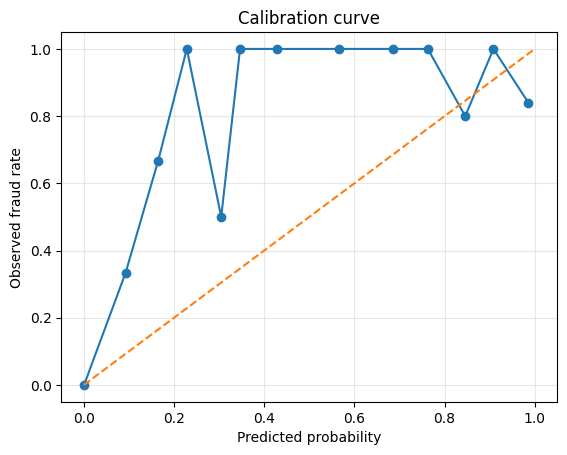

In [13]:
from sklearn.calibration import calibration_curve

y_probs_1 = calib_model_1.predict_proba(X_val)[:, 1]
y_probs_2 = calib_model_2.predict_proba(X_val)[:, 1]

prob_true_1, prob_pred_1 = calibration_curve(
    y_val, y_probs_1, n_bins=15
)

plt.plot(prob_pred_1, prob_true_1, marker='o')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("Predicted probability")
plt.ylabel("Observed fraud rate")
plt.title("Calibration curve")
plt.grid(alpha=0.3)
plt.show()

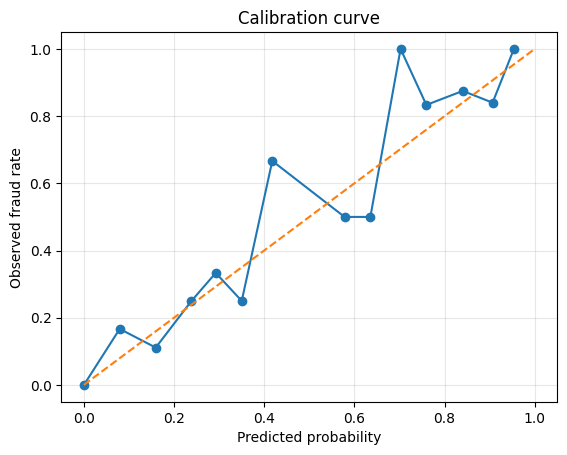

In [14]:
y_probs_2 = calib_model_2.predict_proba(X_val)[:, 1]

prob_true_2, prob_pred_2 = calibration_curve(
    y_val, y_probs_2, n_bins=15
)

plt.plot(prob_pred_2, prob_true_2, marker='o')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("Predicted probability")
plt.ylabel("Observed fraud rate")
plt.title("Calibration curve")
plt.grid(alpha=0.3)
plt.show()

In [15]:
from sklearn.metrics import classification_report, roc_auc_score, precision_recall_curve

y_pred_default_1 = (y_probs_1 >= 0.5).astype(int)
print(classification_report(y_val, y_pred_default_1))

sorted_probs_1 = np.sort(y_probs_1)[::-1]

print("ROC AUC:", roc_auc_score(y_val, y_probs_1))

print('='*60)

y_pred_default_2 = (y_probs_2 >= 0.5).astype(int)
print(classification_report(y_val, y_pred_default_2))

sorted_probs_2 = np.sort(y_probs_2)[::-1]

print("ROC AUC:", roc_auc_score(y_val, y_probs_2))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42655
           1       0.88      0.50      0.64        74

    accuracy                           1.00     42729
   macro avg       0.94      0.75      0.82     42729
weighted avg       1.00      1.00      1.00     42729

ROC AUC: 0.9881820514688876
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42655
           1       0.85      0.77      0.81        74

    accuracy                           1.00     42729
   macro avg       0.93      0.89      0.90     42729
weighted avg       1.00      1.00      1.00     42729

ROC AUC: 0.9889572845615513


Based on above reports, at a treshold of 0.5, model 2 seems to be better. Lets compare different tresholds.

In [16]:
threshold = 0.6
y_custom_1 = (y_probs_1 >= threshold).astype(int)

print(classification_report(y_val, y_custom_1))

threshold = 0.6
y_custom_2 = (y_probs_2 >= threshold).astype(int)

print(classification_report(y_val, y_custom_2))



              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42655
           1       0.88      0.49      0.63        74

    accuracy                           1.00     42729
   macro avg       0.94      0.74      0.81     42729
weighted avg       1.00      1.00      1.00     42729

              precision    recall  f1-score   support

           0       1.00      1.00      1.00     42655
           1       0.86      0.76      0.81        74

    accuracy                           1.00     42729
   macro avg       0.93      0.88      0.90     42729
weighted avg       1.00      1.00      1.00     42729



0.0017318448828664373


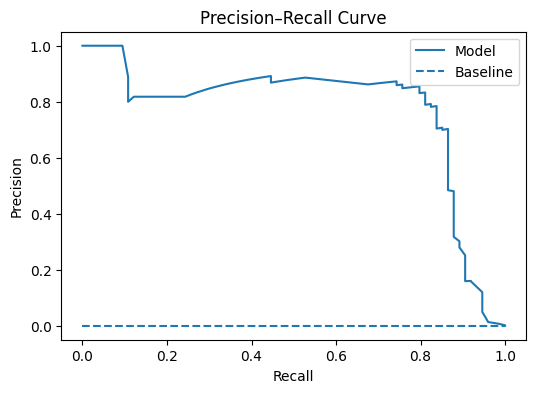

In [17]:
precision, recall, thresholds = precision_recall_curve(y_val, y_probs_2)
fraud_rate = y_val.mean()
print(fraud_rate)


plt.figure(figsize=(6, 4))
plt.plot(recall, precision, label="Model")
plt.hlines(
    y=fraud_rate,
    xmin=0,
    xmax=1,
    linestyles="dashed",
    label="Baseline"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend()
plt.title("Precision–Recall Curve")
plt.show()

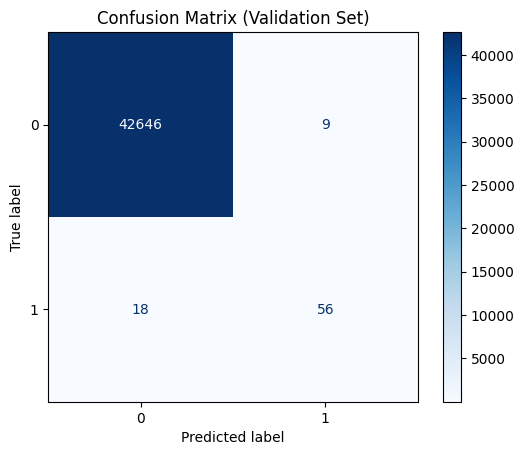

In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_val, y_custom_2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[0, 1]
)

disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix (Validation Set)")
plt.show()


In [19]:
tn, fp, fn, tp = cm.ravel()

print("False positive rate:", fp / (fp + tn))
print("Recall:", tp / (tp + fn))
print("Precision:", tp / (tp + fp))


False positive rate: 0.00021099519399835892
Recall: 0.7567567567567568
Precision: 0.8615384615384616


In [20]:
from sklearn.metrics import precision_score, recall_score

rows = []

for t in np.linspace(0.05, 0.95, 19):
    preds = (y_probs_2 >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_val, preds),
        "recall": recall_score(y_val, preds)
    })

pd.DataFrame(rows)


,threshold,precision,recall
0,0.05,0.666667,0.864865
1,0.10,0.700000,0.851351
2,0.15,0.720930,0.837838
3,0.20,0.765432,0.837838
4,0.25,0.784810,0.837838
5,0.30,0.800000,0.810811
6,0.35,0.833333,0.810811
7,0.40,0.842857,0.797297
8,0.45,0.850746,0.770270
9,0.50,0.850746,0.770270


In [21]:
def evaluate_at_budget(y_true, y_probs, budget_pct=0.005):
    """
    Evaluate model performance at a fixed alert budget.
    
    Args:
        y_true: Ground truth labels
        y_probs: Predicted probabilities
        budget_pct: Maximum % of transactions to flag
    
    Returns:
        dict with threshold, metrics, and business KPIs
    """
    N = int(budget_pct * len(y_true))
    sorted_probs = np.sort(y_probs)[::-1]
    threshold = sorted_probs[N - 1]
    
    y_pred = (y_probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    return {
        'threshold': threshold,
        'budget_pct': budget_pct,
        'n_alerts': fp + tp,
        'recall': tp / (tp + fn),
        'precision': tp / (tp + fp),
        'fpr': fp / (fp + tn),
        'frauds_caught': tp,
        'frauds_missed': fn,
        'false_alarms': fp
    }


for budget in [0.001, 0.005, 0.01, 0.02]:
    result = evaluate_at_budget(y_val, y_probs_2, budget)
    print(f"\nBudget: {budget*100}%")
    print(f"  Recall: {result['recall']:.2%}")
    print(f"  Precision: {result['precision']:.2%}")
    print(f"  Frauds caught: {result['frauds_caught']}/{y_val.sum()}")


Budget: 0.1%
  Recall: 50.00%
  Precision: 88.10%
  Frauds caught: 37/74

Budget: 0.5%
  Recall: 89.19%
  Precision: 30.28%
  Frauds caught: 66/74

Budget: 1.0%
  Recall: 94.59%
  Precision: 12.13%
  Frauds caught: 70/74

Budget: 2.0%
  Recall: 94.59%
  Precision: 5.15%
  Frauds caught: 70/74


In [22]:

def plot_rpo(treshold=0.5):
    """Plots recall vs alert vol, precision vs alert volume and Operating Characteristic Curve
    """
    budgets = np.linspace(0.001, 0.05, 50)
    results = [evaluate_at_budget(y_val, y_probs_2, b) for b in budgets]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Recall vs Budget
    axes[0].plot(budgets * 100, [r['recall'] for r in results], 'b-', linewidth=2)
    axes[0].axvline(treshold, color='r', linestyle='--', label=f'{treshold}%')
    axes[0].set_xlabel('Alert Budget (%)')
    axes[0].set_ylabel('Recall (Fraud Detection Rate)')
    axes[0].set_title('Recall vs Alert Volume')
    axes[0].legend()
    axes[0].grid(alpha=0.3)

    # Precision vs Budget
    axes[1].plot(budgets * 100, [r['precision'] for r in results], 'g-', linewidth=2)
    axes[1].axvline(treshold, color='r', linestyle='--', label=f'{treshold}%')
    axes[1].set_xlabel('Alert Budget (%)')
    axes[1].set_ylabel('Precision (% of Alerts that are Real)')
    axes[1].set_title('Precision vs Alert Volume')
    axes[1].legend()
    axes[1].grid(alpha=0.3)

    # Frauds Caught vs False Alarms
    axes[2].plot([r['false_alarms'] for r in results], 
                [r['frauds_caught'] for r in results], 'purple', linewidth=2)
    axes[2].set_xlabel('False Alarms')
    axes[2].set_ylabel('Frauds Caught')
    axes[2].set_title('Operating Characteristic Curve')
    axes[2].grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

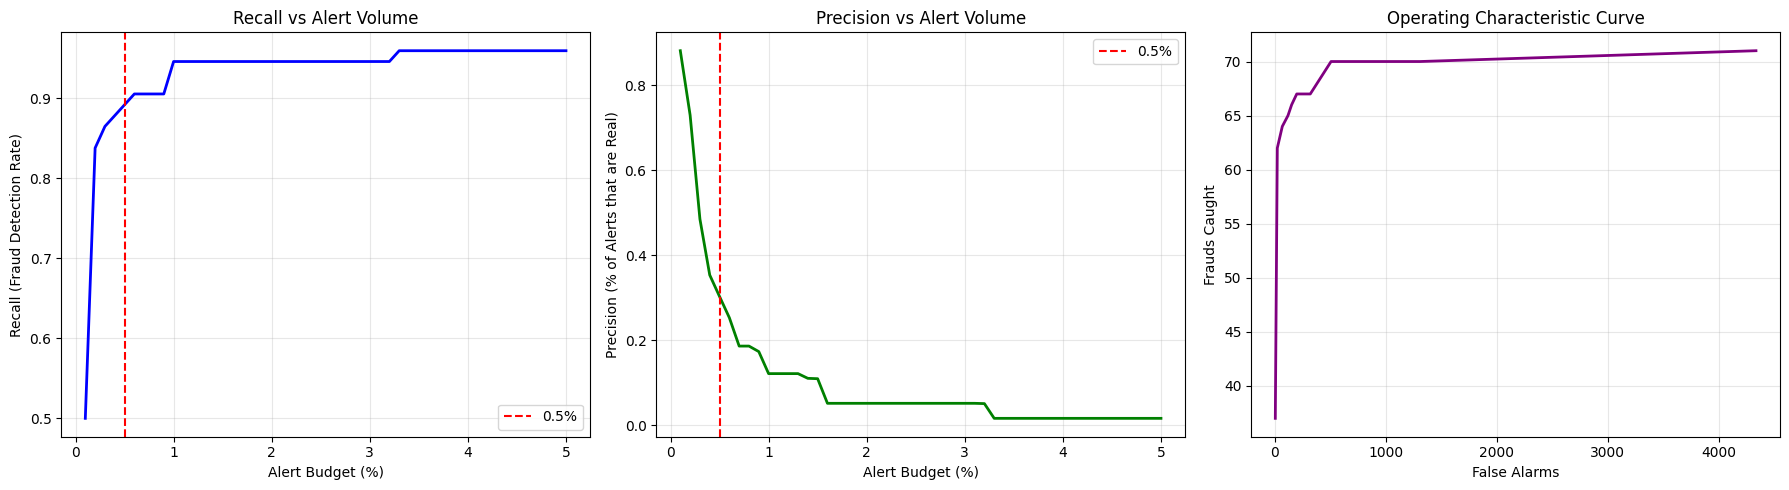

In [23]:
plot_rpo()

In [24]:
def find_optimal_threshold(y_true, y_probs, min_recall=0.90, max_alert_rate=0.02):
    """
    Args:
        y_true: Ground truth labels
        y_probs: Predicted probabilities
        min_recall: Minimum acceptable recall (default 90%)
        max_alert_rate: Maximum % of transactions you can review
    
    Returns:
        dict with recommended threshold and performance metrics
    """
    
    precision, recall, thresholds = precision_recall_curve(y_true, y_probs)
    
    # Find thresholds that meet recall requirement
    valid_indices = np.where(recall[:-1] >= min_recall)[0]
    
    if len(valid_indices) == 0:
        print(f"WARNING: Cannot achieve {min_recall:.0%} recall with this model")
        return None
    
    # Among valid thresholds, find one with best precision
    best_idx = valid_indices[np.argmax(precision[valid_indices])]
    best_threshold = thresholds[best_idx]
    
    # Calculate alert rate
    alert_rate = (y_probs >= best_threshold).mean()
    
    # Make predictions with this threshold
    y_pred = (y_probs >= best_threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    result = {
        'threshold': best_threshold,
        'recall': recall[best_idx],
        'precision': precision[best_idx],
        'alert_rate': alert_rate,
        'frauds_caught': tp,
        'frauds_missed': fn,
        'total_frauds': tp + fn,
        'false_alarms': fp,
        'total_alerts': tp + fp,
        'f2_score': (5 * precision[best_idx] * recall[best_idx]) / (4 * precision[best_idx] + recall[best_idx])
    }
    
    print(f"\n{'='*60}")
    print(f"RECOMMENDED THRESHOLD: {best_threshold:.4f}")
    print(f"{'='*60}")
    print(f"Recall (Fraud Detection Rate): {result['recall']:.2%}")
    print(f"Precision (Alert Accuracy):     {result['precision']:.2%}")
    print(f"Alert Rate:                     {result['alert_rate']:.2%}")
    print(f"\nBusiness Impact:")
    print(f"  Frauds caught:  {result['frauds_caught']}/{result['total_frauds']} ({result['recall']:.1%})")
    print(f"  Frauds missed:  {result['frauds_missed']}/{result['total_frauds']} ({fn/(tp+fn):.1%})")
    print(f"  False alarms:  {result['false_alarms']} ({result['false_alarms']/len(y_true):.2%} of all transactions)")
    print(f"  Total alerts:  {result['total_alerts']} ({result['alert_rate']:.2%} of transactions)")
    
    if alert_rate > max_alert_rate:
        print(f"\n⚠️  WARNING: Alert rate {alert_rate:.2%} exceeds budget of {max_alert_rate:.2%}")
        print(f"    Consider: lower recall target or increase review capacity")
    
    return result

# Find the optimal threshold
optimal = find_optimal_threshold(
    y_val, 
    y_probs_2, 
    min_recall=0.90,  
    max_alert_rate=0.02
)


RECOMMENDED THRESHOLD: 0.0127
Recall (Fraud Detection Rate): 90.54%
Precision (Alert Accuracy):     25.28%
Alert Rate:                     0.62%

Business Impact:
  Frauds caught:  67/74 (90.5%)
  Frauds missed:  7/74 (9.5%)
  False alarms:  198 (0.46% of all transactions)
  Total alerts:  265 (0.62% of transactions)


In [25]:
def evaluate_at_threshold(y_true, y_probs, threshold=0.5):
    y_pred = (y_probs >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    
    n_alerts = fp + tp
    budget_pct = n_alerts / len(y_true)
    
    return {
        'threshold': threshold,
        'budget_pct': budget_pct,
        'n_alerts': n_alerts,
        'recall': tp / (tp + fn) if (tp + fn) > 0 else 0,
        'precision': tp / (tp + fp) if (tp + fp) > 0 else 0,
        'fpr': fp / (fp + tn) if (fp + tn) > 0 else 0,
        'frauds_caught': tp,
        'frauds_missed': fn,
        'false_alarms': fp
    }

In [26]:
evaluate_at_threshold(y_val, y_probs_2, threshold=optimal['threshold'] )

{'threshold': np.float64(0.012687898903374717),
 'budget_pct': np.float64(0.00620187694540008),
 'n_alerts': np.int64(265),
 'recall': np.float64(0.9054054054054054),
 'precision': np.float64(0.2528301886792453),
 'fpr': np.float64(0.0046418942679638964),
 'frauds_caught': np.int64(67),
 'frauds_missed': np.int64(7),
 'false_alarms': np.int64(198)}

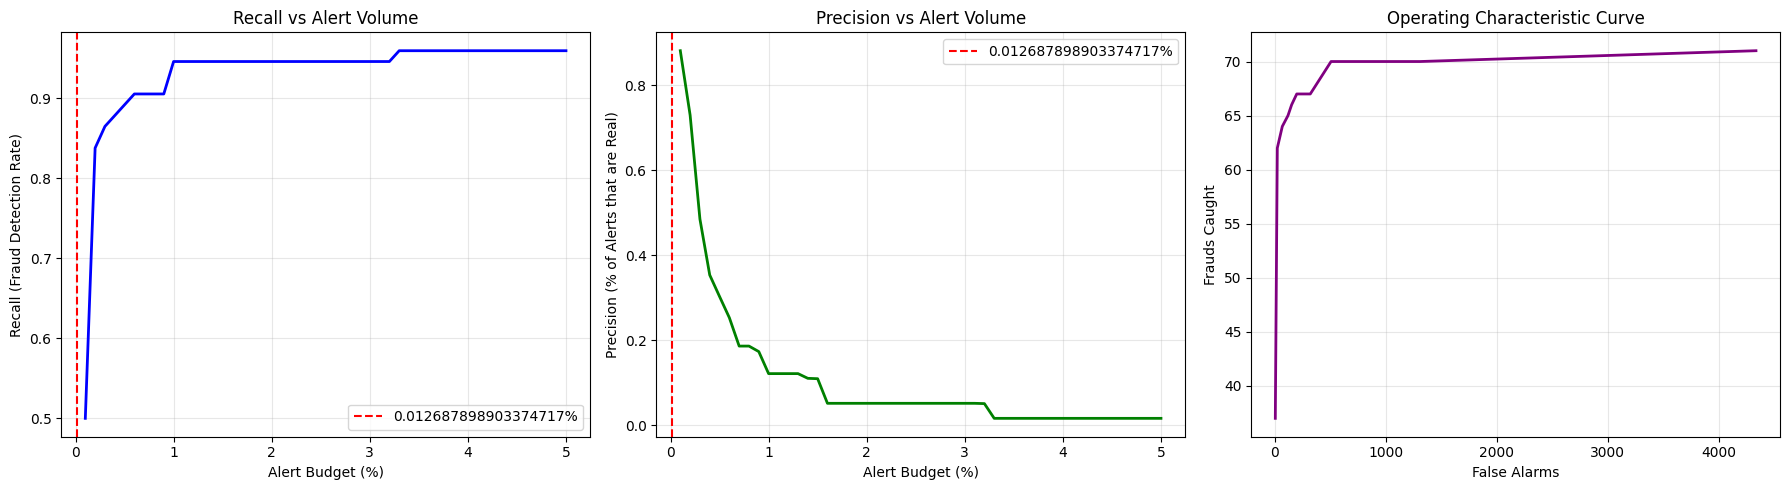

In [27]:
plot_rpo(treshold=optimal['threshold'])

In [28]:
y_test_probs = calib_model_2.predict_proba(X_test)[:, 1]
test_preds = (y_test_probs >= optimal["threshold"]).astype(int)

In [29]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, test_preds))

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

print({
    "recall": tp / (tp + fn),
    "precision": tp / (tp + fp),
    "fpr": fp / (fp + tn),
    "frauds_caught": tp,
    "frauds_missed": fn,
    "false_alarms": fp,
    "alert_rate": (tp + fp) / len(y_test)
})

              precision    recall  f1-score   support

           0       1.00      0.99      1.00     42648
           1       0.21      0.81      0.33        74

    accuracy                           0.99     42722
   macro avg       0.60      0.90      0.66     42722
weighted avg       1.00      0.99      1.00     42722

{'recall': np.float64(0.8108108108108109), 'precision': np.float64(0.20761245674740483), 'fpr': np.float64(0.005369536672294129), 'frauds_caught': np.int64(60), 'frauds_missed': np.int64(14), 'false_alarms': np.int64(229), 'alert_rate': np.float64(0.006764664575628482)}


In [30]:
from xgboost import XGBClassifier

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()


xgb = XGBClassifier(n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=neg_count / pos_count,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1)

calib_xgb = CalibratedClassifierCV(
    xgb,
    method="sigmoid",
    cv=None
)

calib_xgb.fit(X_train, y_train)

y_prob_xgb_cal = calib_xgb.predict_proba(X_test)[:, 1]

In [31]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=neg_count / pos_count,
    objective="binary",
    metric="auc_pr",
    random_state=42,
    n_jobs=-1
)

calib_lgb = CalibratedClassifierCV(
    lgbm,
    method="sigmoid",
    cv=None
)

calib_lgb.fit(X_train, y_train)

y_prob_lgb_cal = calib_lgb.predict_proba(X_test)[:, 1]


[LightGBM] [Info] Number of positive: 275, number of negative: 159209
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.014075 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7905
[LightGBM] [Info] Number of data points in the train set: 159484, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.001724 -> initscore=-6.361202
[LightGBM] [Info] Start training from score -6.361202
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gai

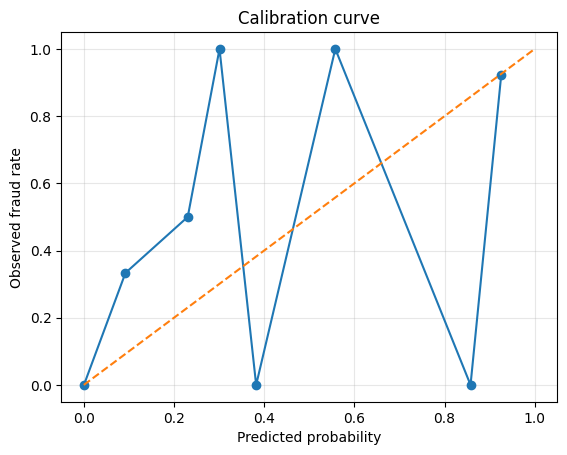

In [32]:
y_probs_xgb = calib_xgb.predict_proba(X_val)[:, 1]

prob_true_xgb, prob_pred_xgb = calibration_curve(
    y_val, y_probs_xgb, n_bins=15
)

plt.plot(prob_pred_xgb, prob_true_xgb, marker='o')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("Predicted probability")
plt.ylabel("Observed fraud rate")
plt.title("Calibration curve")
plt.grid(alpha=0.3)
plt.show()

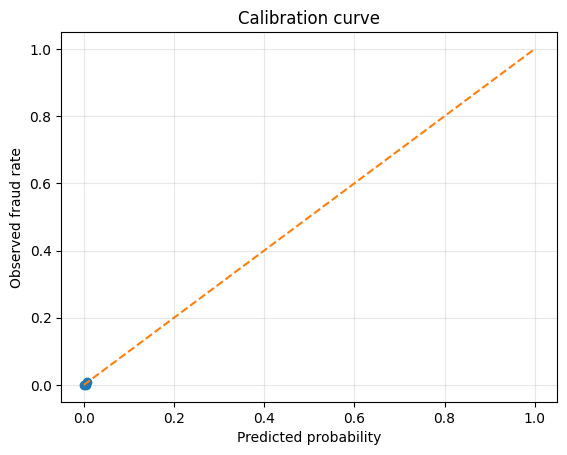

In [33]:
y_probs_lgbm = calib_lgb.predict_proba(X_val)[:, 1]

prob_true_lgbm, prob_pred_lgbm = calibration_curve(
    y_val, y_probs_lgbm, n_bins=5, strategy="quantile"
)

plt.plot(prob_pred_lgbm, prob_true_lgbm, marker='o')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("Predicted probability")
plt.ylabel("Observed fraud rate")
plt.title("Calibration curve")
plt.grid(alpha=0.3)
plt.show()

In [49]:
optimal_lgb = find_optimal_threshold(y_true=y_val,y_probs=y_probs_lgbm, min_recall=0.89, max_alert_rate=0.03)



RECOMMENDED THRESHOLD: 0.0115
Recall (Fraud Detection Rate): 89.19%
Precision (Alert Accuracy):     7.33%
Alert Rate:                     2.11%

Business Impact:
  Frauds caught:  66/74 (89.2%)
  Frauds missed:  8/74 (10.8%)
  False alarms:  835 (1.95% of all transactions)
  Total alerts:  901 (2.11% of transactions)


In [50]:
optimal_xgb = find_optimal_threshold(y_true=y_val,y_probs=y_probs_xgb, max_alert_rate=0.03)


RECOMMENDED THRESHOLD: 0.0003
Recall (Fraud Detection Rate): 90.54%
Precision (Alert Accuracy):     10.55%
Alert Rate:                     1.49%

Business Impact:
  Frauds caught:  67/74 (90.5%)
  Frauds missed:  7/74 (9.5%)
  False alarms:  568 (1.33% of all transactions)
  Total alerts:  635 (1.49% of transactions)


In [51]:
y_pred_xgb = (y_probs_xgb >= 0.0003).astype(int)
print(classification_report(y_val, y_pred_xgb))

sorted_probs_xgb = np.sort(y_probs_xgb)[::-1]

print("ROC AUC:", roc_auc_score(y_val, y_probs_xgb))

print('='*60)

y_pred_default_lgb = (y_probs_lgbm >= 0.0129).astype(int)
print(classification_report(y_val, y_pred_default_lgb))

sorted_probs_lgb = np.sort(y_probs_lgbm)[::-1]

print("ROC AUC:", roc_auc_score(y_val, y_probs_lgbm))

              precision    recall  f1-score   support

           0       0.00      0.00      0.00     42655
           1       0.00      1.00      0.00        74

    accuracy                           0.00     42729
   macro avg       0.00      0.50      0.00     42729
weighted avg       0.00      0.00      0.00     42729

ROC AUC: 0.9852521962825562
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     42655
           1       0.12      0.88      0.21        74

    accuracy                           0.99     42729
   macro avg       0.56      0.93      0.60     42729
weighted avg       1.00      0.99      0.99     42729

ROC AUC: 0.9603043906642547


c:\Users\h4voc\PycharmProjects\ML-Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\h4voc\PycharmProjects\ML-Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\h4voc\PycharmProjects\ML-Project\.venv\Lib\site-packages\sklearn\metrics\_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{me

In [52]:
y_test_probs_xgb = calib_xgb.predict_proba(X_test)[:, 1]
test_preds = (y_test_probs_xgb >= optimal_xgb["threshold"]).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print('=' * 60)
print("XGB MODEL")
print('=' * 60)

print(classification_report(y_test, test_preds))

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

print({
    "recall": tp / (tp + fn),
    "precision": tp / (tp + fp),
    "fpr": fp / (fp + tn),
    "frauds_caught": tp,
    "frauds_missed": fn,
    "false_alarms": fp,
    "alert_rate": (tp + fp) / len(y_test)
})

print('='*80)

y_test_probs_lgb = calib_lgb.predict_proba(X_test)[:, 1]
test_preds = (y_test_probs_lgb >= optimal_lgb["threshold"]).astype(int)


print('=' * 60)
print("LGBM MODEL")
print('=' * 60)

print(classification_report(y_test, test_preds))

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

print({
    "recall": tp / (tp + fn),
    "precision": tp / (tp + fp),
    "fpr": fp / (fp + tn),
    "frauds_caught": tp,
    "frauds_missed": fn,
    "false_alarms": fp,
    "alert_rate": (tp + fp) / len(y_test)
})

print('=' * 60)
print("LOGISTIC REGRESSION MODEL")
print('=' * 60)
y_test_probs = calib_model_2.predict_proba(X_test)[:, 1]
test_preds = (y_test_probs >= optimal["threshold"]).astype(int)



print(classification_report(y_test, test_preds))

cm = confusion_matrix(y_test, test_preds)
tn, fp, fn, tp = cm.ravel()

print({
    "recall": tp / (tp + fn),
    "precision": tp / (tp + fp),
    "fpr": fp / (fp + tn),
    "frauds_caught": tp,
    "frauds_missed": fn,
    "false_alarms": fp,
    "alert_rate": (tp + fp) / len(y_test)
})

XGB MODEL
              precision    recall  f1-score   support

           0       1.00      0.99      0.99     42648
           1       0.11      0.88      0.19        74

    accuracy                           0.99     42722
   macro avg       0.55      0.93      0.59     42722
weighted avg       1.00      0.99      0.99     42722

{'recall': np.float64(0.8783783783783784), 'precision': np.float64(0.10517799352750809), 'fpr': np.float64(0.01296661039204652), 'frauds_caught': np.int64(65), 'frauds_missed': np.int64(9), 'false_alarms': np.int64(553), 'alert_rate': np.float64(0.01446561490566921)}
LGBM MODEL
              precision    recall  f1-score   support

           0       1.00      0.98      0.99     42648
           1       0.07      0.85      0.13        74

    accuracy                           0.98     42722
   macro avg       0.53      0.92      0.56     42722
weighted avg       1.00      0.98      0.99     42722

{'recall': np.float64(0.8513513513513513), 'precision': n

With the assumption that each alert (false or true) costs $200 to review, I will compare each models cost per fraud caught

In [56]:
review_cost = 200

xgb_alerts = 65 + 553
lgbm_alerts = 63 + 835
lgr_alerts = 60 + 229

print(f"XGB_cost: ${xgb_alerts * review_cost}")
print(f"LGB_cost: ${lgbm_alerts * review_cost}")
print(f"LGR_cost: ${lgr_alerts * review_cost}")

xgb_cost_per_fraud = (xgb_alerts * review_cost) / 65
lgbm_cost_per_fraud = (lgbm_alerts * review_cost) / 63
lgr_cost_per_fraud = (lgr_alerts * review_cost) / 60

print(round(xgb_cost_per_fraud))
print(round(lgbm_cost_per_fraud))
print(round(lgr_cost_per_fraud))


XGB_cost: $123600
LGB_cost: $179600
LGR_cost: $57800
1902
2851
963


Note that LGBM, LGR, XGB have almost similar recall (or sensitivity) however LGR has a lower operational cost with the assumption of $200 per review of a fraud case.
It is worth to mention the performance of XGBoost is slightly better with a higher recall but the operational cost is quite high
Based on this, I will choose the LGR model for a similar recall and low operational cost.

In [57]:
import joblib
from datetime import datetime

deployment_artifact = {
    "model": calib_model_2,
    "threshold": optimal['threshold'],
    "trained_at": datetime.now().isoformat(),
    "features": X.columns.tolist(),
    "model_type": "Calibrated LGR"
}

joblib.dump(deployment_artifact, "fraud_model_v1_lgr.pkl")
print("done")

done
